In [ ]:
# SETUP MANDIRI: menyiapkan folder, kode src/, dan dataset (SEED 1083) bila sesi baru
import os, sys, subprocess
ROOT = "/content/simuteh-2330511083"
for d in ["data/sintetis", "notebook", "src", "hasil", "laporan"]:
    os.makedirs(f"{ROOT}/{d}", exist_ok=True)
FILES = {'src/utils_cv.py': '"""utils_cv.py: fungsi bantu yang dipakai ulang sepanjang semester."""\nimport cv2\nimport numpy as np\nimport matplotlib.pyplot as plt\n\n\ndef baca(path):\n    """Membaca citra dan langsung memberi pesan jelas bila gagal."""\n    img = cv2.imread(path)\n    if img is None:\n        raise FileNotFoundError(f"Citra tidak ditemukan: {path}")\n    return img\n\n\ndef tampil(daftar, judul, baris=1, ukuran=(14, 4)):\n    """Menampilkan beberapa citra berdampingan. Citra 3 kanal dianggap BGR."""\n    kolom = int(np.ceil(len(daftar) / baris))\n    plt.figure(figsize=ukuran)\n    for i, (im, jd) in enumerate(zip(daftar, judul)):\n        plt.subplot(baris, kolom, i + 1)\n        if im.ndim == 3:\n            plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))\n        else:\n            plt.imshow(im, cmap="gray", vmin=0, vmax=255)\n        plt.title(jd)\n        plt.axis("off")\n    plt.tight_layout()\n\n\ndef kontras_bercak(kanal, mask_daun, mask_bercak):\n    """KB = |rerata bercak - rerata daun sehat| / simpangan baku daun sehat."""\n    k = kanal.astype(np.float64)\n    sehat = (mask_daun > 0) & (mask_bercak == 0)\n    bercak = mask_bercak > 0\n    if bercak.sum() == 0:\n        return float("nan")\n    return abs(k[bercak].mean() - k[sehat].mean()) / (k[sehat].std() + 1e-6)\n\n\ndef statistik(gray):\n    """Ringkasan statistik intensitas untuk mendiagnosis mutu citra."""\n    return {"rerata": round(float(gray.mean()), 1),\n            "simpangan_baku": round(float(gray.std()), 1),\n            "min": int(gray.min()), "maks": int(gray.max()),\n            "persen_gelap": round(100 * float((gray < 50).mean()), 1),\n            "persen_terang": round(100 * float((gray > 205).mean()), 1)}', 'src/buat_dataset_sintetis.py': '"""\nbuat_dataset_sintetis.py\nMembangkitkan dataset citra sintetis daun teh untuk studi kasus SIMUTEH.\n"""\nimport os\nimport csv\nimport cv2\nimport numpy as np\n\nSEED = 1083          # 4 digit terakhir NIM 2330511083\nN_PER_KELAS = 20\nH, W = 480, 640\nKELAS = ["sehat", "ringan", "berat"]\nKONDISI = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]\nOUT = os.path.join("data", "sintetis")\nrng = np.random.default_rng(SEED)\n\n\ndef gambar_daun(img, mask):\n    """Menggambar satu helai daun berbentuk elips beserta tulang daunnya."""\n    cx = int(rng.integers(260, 380))\n    cy = int(rng.integers(200, 280))\n    ax = int(rng.integers(190, 240))\n    ay = int(rng.integers(95, 125))\n    sudut = float(rng.uniform(-25, 25))\n    hijau = np.array([rng.integers(35, 60), rng.integers(120, 150),\n                      rng.integers(45, 75)])  # BGR\n    cv2.ellipse(img, (cx, cy), (ax, ay), sudut, 0, 360, hijau.tolist(), -1)\n    cv2.ellipse(mask, (cx, cy), (ax, ay), sudut, 0, 360, 255, -1)\n    # tulang daun utama dan cabang\n    t = np.deg2rad(sudut)\n    p1 = (int(cx - ax * np.cos(t)), int(cy - ax * np.sin(t)))\n    p2 = (int(cx + ax * np.cos(t)), int(cy + ax * np.sin(t)))\n    tulang = (hijau * 1.35).clip(0, 255).tolist()\n    cv2.line(img, p1, p2, tulang, 3)\n    for k in np.linspace(-0.7, 0.7, 6):\n        bx, by = cx + k * ax * np.cos(t), cy + k * ax * np.sin(t)\n        for arah in (-1, 1):\n            ex = bx + 0.35 * ax * np.cos(t + arah * 1.0)\n            ey = by + 0.35 * ax * np.sin(t + arah * 1.0)\n            cv2.line(img, (int(bx), int(by)), (int(ex), int(ey)), tulang, 1)\n    return mask\n\n\ndef gambar_bercak(img, mask_daun, mask_bercak, kelas):\n    """Menambahkan bercak cacar daun (pucat kekuningan, tepi kecokelatan)."""\n    if kelas == "sehat":\n        return\n    n = int(rng.integers(1, 4)) if kelas == "ringan" else int(rng.integers(6, 13))\n    r_min, r_maks = (3, 7) if kelas == "ringan" else (5, 14)\n    ys, xs = np.where(mask_daun > 0)\n    for _ in range(n):\n        i = int(rng.integers(0, len(xs)))\n        r = int(rng.integers(r_min, r_maks + 1))\n        pusat = (int(xs[i]), int(ys[i]))\n        warna = [int(rng.integers(70, 100)), int(rng.integers(165, 190)),\n                 int(rng.integers(185, 210))]  # BGR pucat\n        cv2.circle(img, pusat, r + 2, (40, 80, 110), -1)  # tepi cokelat\n        cv2.circle(img, pusat, r, warna, -1)\n        cv2.circle(mask_bercak, pusat, r + 2, 255, -1)\n    mask_bercak &= mask_daun  # bercak hanya di daun\n\n\ndef ganggu_cahaya(img, kondisi):\n    """Mensimulasikan kondisi pemotretan di lapangan."""\n    f = img.astype(np.float32)\n    if kondisi == "gelap":\n        f = 255 * (f / 255) ** 2.0\n    elif kondisi == "terang":\n        f = 255 * (f / 255) ** 0.45\n    elif kondisi == "kontras_rendah":\n        f = 0.35 * f + 95\n    elif kondisi == "bayangan":\n        gx = np.linspace(1.15, 0.30, W, dtype=np.float32)  # separuh teduh\n        f = f * gx[None, :, None]\n    sigma = float(rng.uniform(6, 14))\n    f = f + rng.normal(0, sigma, f.shape)  # derau sensor\n    return np.clip(f, 0, 255).astype(np.uint8)\n\n\ndef main():\n    for sub in ["citra", "bersih", "mask_daun", "mask_bercak"]:\n        os.makedirs(os.path.join(OUT, sub), exist_ok=True)\n    baris = []\n    nomor = 0\n    for kelas in KELAS:\n        for j in range(N_PER_KELAS):\n            nomor += 1\n            latar = np.array([rng.integers(150, 190), rng.integers(170, 205),\n                              rng.integers(185, 215)])  # nampan anyaman\n            img = np.ones((H, W, 3), np.uint8) * latar.astype(np.uint8)\n            img = cv2.add(img, rng.integers(0, 12, (H, W, 3)).astype(np.uint8))\n            m_daun = np.zeros((H, W), np.uint8)\n            m_bercak = np.zeros((H, W), np.uint8)\n            gambar_daun(img, m_daun)\n            gambar_bercak(img, m_daun, m_bercak, kelas)\n            bersih = cv2.GaussianBlur(img, (3, 3), 0.8)\n            kondisi = KONDISI[j % len(KONDISI)]\n            citra = ganggu_cahaya(bersih, kondisi)\n            nama = f"teh_{nomor:03d}.png"\n            cv2.imwrite(os.path.join(OUT, "citra", nama), citra)\n            cv2.imwrite(os.path.join(OUT, "bersih", nama), bersih)\n            cv2.imwrite(os.path.join(OUT, "mask_daun", nama), m_daun)\n            cv2.imwrite(os.path.join(OUT, "mask_bercak", nama), m_bercak)\n            persen = 100 * (m_bercak > 0).sum() / max((m_daun > 0).sum(), 1)\n            baris.append([nama, kelas, kondisi, round(persen, 2)])\n    with open(os.path.join(OUT, "label.csv"), "w", newline="") as f:\n        w = csv.writer(f)\n        w.writerow(["nama_file", "kelas", "kondisi_cahaya", "persen_bercak"])\n        w.writerows(baris)\n    print(f"Selesai: {nomor} citra tersimpan di {OUT}")\n\n\nif __name__ == "__main__":\n    main()', 'src/praproses.py': '"""praproses.py: rangkaian praproses SIMUTEH (dipakai ulang mulai P5)."""\nimport json\nimport cv2\nimport numpy as np\n\nPARAM_BAWAAN = {\n    "lebar": 640,        # sampling: lebar citra kerja (piksel)\n    "gamma": 1.0,        # < 1 mencerahkan, > 1 menggelapkan\n    "clahe_clip": 2.0,   # 0 berarti CLAHE tidak dipakai\n    "clahe_tile": 8,\n    "penapis": "median", # "none", "rerata", "gaussian", "median"\n    "kernel": 3,\n    "sigma": 1.0,\n    "tajam_k": 0.0,      # 0 berarti tanpa penajaman\n}\n\ndef praproses(img_bgr, p=None):\n    """Urutan: ubah ukuran -> gamma -> CLAHE kanal V -> redam derau -> tajamkan."""\n    p = {**PARAM_BAWAAN, **(p or {})}\n\n    # 1. Ubah ukuran: lebar = p["lebar"], rasio aspek tetap, INTER_AREA\n    h, w = img_bgr.shape[:2]\n    tinggi = int(round(h * p["lebar"] / w))\n    img = cv2.resize(img_bgr, (p["lebar"], tinggi), interpolation=cv2.INTER_AREA)\n\n    # 2. Koreksi gamma lewat tabel LUT (hanya bila gamma != 1)\n    if p["gamma"] != 1:\n        lut = np.array([255 * (i / 255) ** p["gamma"] for i in range(256)])\n        img = cv2.LUT(img, lut.clip(0, 255).astype(np.uint8))\n\n    # 3. CLAHE hanya pada kanal V (HSV), lalu kembali ke BGR\n    if p["clahe_clip"] > 0:\n        clahe = cv2.createCLAHE(clipLimit=p["clahe_clip"],\n                                tileGridSize=(p["clahe_tile"], p["clahe_tile"]))\n        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)\n        hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])\n        img = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)\n\n    # 4. Redam derau (ukuran kernel harus ganjil)\n    k = int(p["kernel"])\n    if p["penapis"] == "rerata":\n        img = cv2.blur(img, (k, k))\n    elif p["penapis"] == "gaussian":\n        img = cv2.GaussianBlur(img, (k, k), p["sigma"])\n    elif p["penapis"] == "median":\n        img = cv2.medianBlur(img, k)\n    # "none": tidak melakukan apa-apa\n\n    # 5. Unsharp masking: citra + k * (citra - blur)\n    if p["tajam_k"] > 0:\n        blur = cv2.GaussianBlur(img, (5, 5), 1.0)\n        img = cv2.addWeighted(img, 1 + p["tajam_k"], blur, -p["tajam_k"], 0)\n\n    return img\n\ndef simpan_param(p, path="../hasil/param_praproses.json"):\n    with open(path, "w") as f:\n        json.dump({**PARAM_BAWAAN, **p}, f, indent=2)'}
for p, t in FILES.items():
    if not os.path.exists(f"{ROOT}/{p}"):
        open(f"{ROOT}/{p}", "w").write(t)
os.chdir(ROOT)
if not os.path.exists("data/sintetis/label.csv"):
    print(subprocess.run([sys.executable, "src/buat_dataset_sintetis.py"], capture_output=True, text=True).stdout)
os.chdir(f"{ROOT}/notebook")


In [116]:
# === B2 ===
%cd /content/simuteh-2330511083/notebook
import sys
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil, kontras_bercak

/content/simuteh-2330511083/notebook


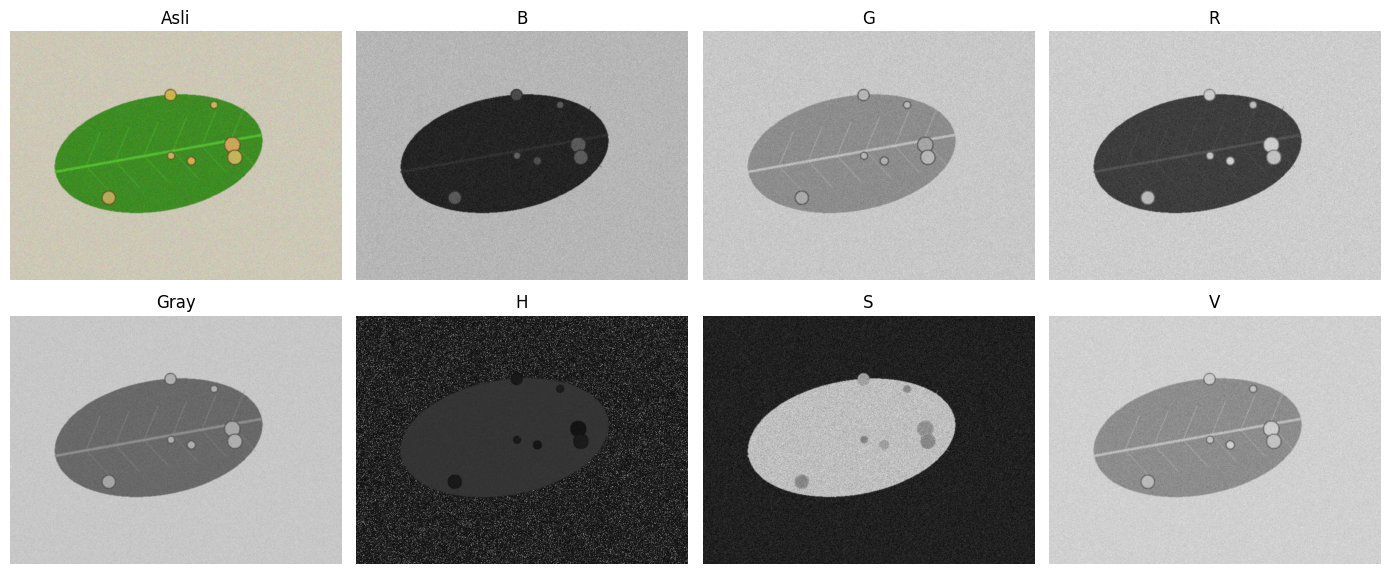

KB kanal B   : 3.64
KB kanal G   : 0.60
KB kanal R   : 9.95
KB kanal Gray: 4.57
KB kanal H   : 8.26
KB kanal S   : 2.47
KB kanal V   : 2.35


In [117]:
nama = "teh_041.png"
img = baca(f"../data/sintetis/citra/{nama}")
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
b, g, r = cv2.split(img)
h, s, v = cv2.split(hsv)
kanal = {"B": b, "G": g, "R": r, "Gray": gray, "H": h, "S": s, "V": v}

tampil([img] + list(kanal.values()), ["Asli"] + list(kanal.keys()),
       baris=2, ukuran=(14, 6))
plt.savefig("../hasil/b2_panel_kanal.png"); plt.show()

for nm, c in kanal.items():
    print(f"KB kanal {nm:4s}: {kontras_bercak(c, md, mb):.2f}")

fx=0.5: ukuran (240, 320), KB=5.32
fx=0.2: ukuran (96, 128), KB=4.56
fx=0.1: ukuran (48, 64), KB=3.06
fx=0.05: ukuran (24, 32), KB=1.57
k=1: 2 level, KB=3.71
k=2: 3 level, KB=3.72
k=3: 6 level, KB=3.88
k=4: 11 level, KB=4.22
k=8: 154 level, KB=4.57


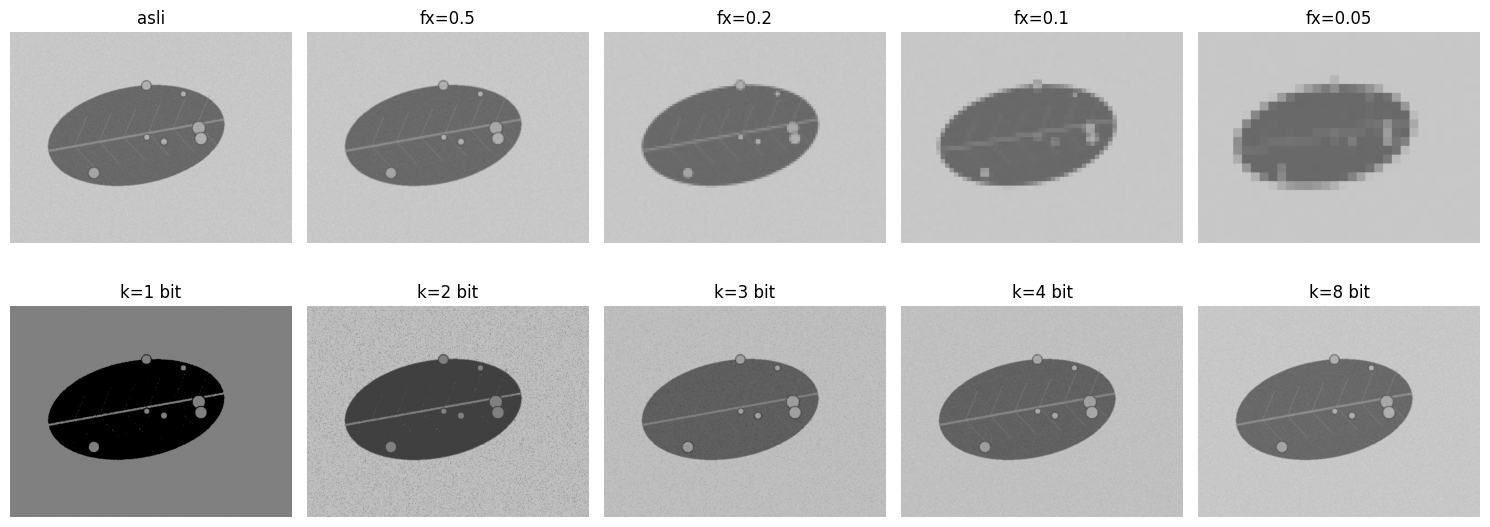

In [118]:
fig, ax = plt.subplots(2, 5, figsize=(15, 6))
ax[0,0].imshow(gray, cmap="gray", vmin=0, vmax=255); ax[0,0].set_title("asli")
for i, fx in enumerate([0.5, 0.2, 0.1, 0.05]):
    kecil = cv2.resize(gray, None, fx=fx, fy=fx, interpolation=cv2.INTER_AREA)
    besar = cv2.resize(kecil, gray.shape[::-1], interpolation=cv2.INTER_NEAREST)
    print(f"fx={fx}: ukuran {kecil.shape}, KB={kontras_bercak(besar, md, mb):.2f}")
    ax[0,i+1].imshow(besar, cmap="gray", vmin=0, vmax=255); ax[0,i+1].set_title(f"fx={fx}")

for i, k in enumerate([1, 2, 3, 4, 8]):
    langkah = 256 // (2 ** k)
    kuant = (gray // langkah) * langkah
    print(f"k={k}: {len(np.unique(kuant))} level, KB={kontras_bercak(kuant, md, mb):.2f}")
    ax[1,i].imshow(kuant, cmap="gray", vmin=0, vmax=255); ax[1,i].set_title(f"k={k} bit")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig("../hasil/b2_sampling_kuantisasi.png"); plt.show()

In [119]:
def semua_kanal(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    b, g, r = cv2.split(img); h, s, v = cv2.split(hsv)
    return {"B": b, "G": g, "R": r,
            "Gray": cv2.cvtColor(img, cv2.COLOR_BGR2GRAY),
            "H": h, "S": s, "V": v}

label = pd.read_csv("../data/sintetis/label.csv")
baris = []
for _, d in label[label.kelas == "berat"].iterrows():
    im = baca(f"../data/sintetis/citra/{d.nama_file}")
    m_d = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    m_b = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
    kb = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()}
    kb["kondisi"] = d.kondisi_cahaya
    baris.append(kb)

tabel_kb = pd.DataFrame(baris).groupby("kondisi").mean().round(2)
print(tabel_kb)
tabel_kb.to_csv("../hasil/b2_kb_kanal.csv")

                   B     G     R  Gray     H     S     V
kondisi                                                 
bayangan        1.62  0.52  5.34  1.91  4.08  0.92  1.26
gelap           1.32  1.02  9.98  4.09  6.08  0.90  2.79
kontras_rendah  0.93  0.13  4.03  1.98  2.48  0.34  1.09
normal          2.28  0.51  8.55  3.95  6.72  1.56  2.00
terang          1.45  0.66  6.67  3.46  5.13  0.46  1.83


In [120]:
baris = []
for _, d in label[label.kelas == "ringan"].iterrows():
    im = baca(f"../data/sintetis/citra/{d.nama_file}")
    m_d = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    m_b = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
    kb = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()}
    kb["kondisi"] = d.kondisi_cahaya
    baris.append(kb)
tabel_kb_ringan = pd.DataFrame(baris).groupby("kondisi").mean().round(2)
print(tabel_kb_ringan)
tabel_kb_ringan.to_csv("../hasil/b2_kb_kanal_ringan.csv")

                   B     G     R  Gray     H     S     V
kondisi                                                 
bayangan        0.69  0.36  4.76  1.24  4.97  0.71  0.68
gelap           0.64  0.50  9.87  2.52  7.58  1.00  1.56
kontras_rendah  0.69  0.10  3.42  1.49  2.00  0.24  0.90
normal          1.49  0.84  9.31  3.12  8.83  1.44  1.31
terang          1.35  0.77  6.41  2.57  5.92  1.14  0.89


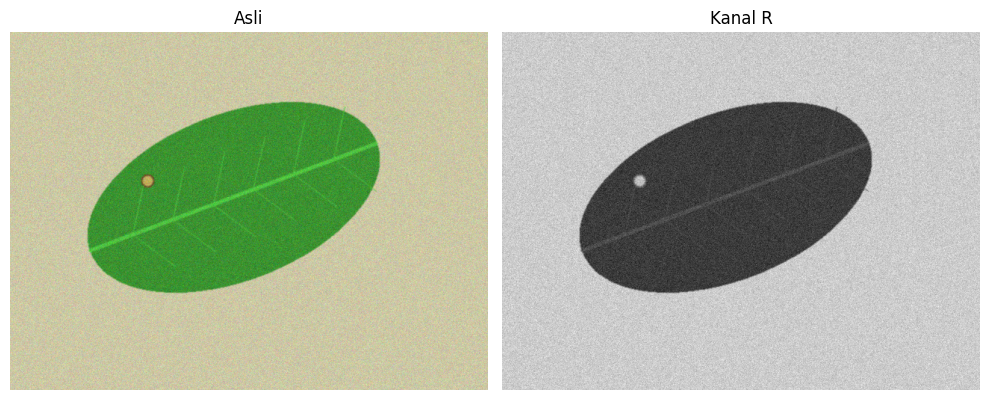

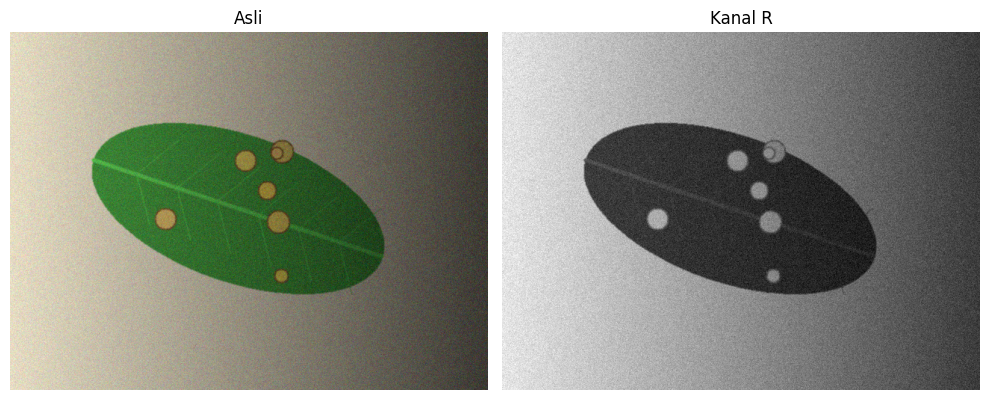

In [121]:
KANAL_TERBAIK = "R"
for nm in ["teh_021.png", "teh_045.png"]:
    im = baca(f"../data/sintetis/citra/{nm}")
    c = semua_kanal(im)[KANAL_TERBAIK]
    tampil([im, c], ["Asli", f"Kanal {KANAL_TERBAIK}"], ukuran=(10, 4))
    plt.savefig(f"../hasil/b2_terbaik_{nm[:-4]}.png"); plt.show()

In [122]:
bercak = np.uint8([[[86, 178, 196]]])
daun   = np.uint8([[[60, 136, 52]]])
for nm, px in {"bercak": bercak, "daun": daun}.items():
    print(nm, "gray:", cv2.cvtColor(px, cv2.COLOR_BGR2GRAY)[0,0],
          "| HSV:", cv2.cvtColor(px, cv2.COLOR_BGR2HSV)[0,0])

bercak gray: 173 | HSV: [ 25 143 196]
daun gray: 102 | HSV: [ 63 158 136]
